# 04 — Clustering provinsi berdasarkan pola harga (Q8)

**Pertanyaan:** bisakah provinsi dikelompokkan berdasarkan pola harganya?

**Keputusan terkait:** strategi procurement per kelompok wilayah. Daripada membuat 34 strategi,
tim cukup punya beberapa playbook.

**Fitur** (pasar tradisional, per provinsi):

| Fitur | Definisi | Periode |
|---|---|---|
| `level_pokok` | harga provinsi ÷ nasional − 1, rata-rata beras, gula, minyak goreng | Nov 2023 – Okt 2026 |
| `level_protein` | sama, untuk daging sapi, daging ayam, telur | Nov 2023 – Okt 2026 |
| `level_bumbu` | sama, untuk cabai, bawang merah, bawang putih | Nov 2023 – Okt 2026 |
| `ayunan_cabai_bawang` | rata-rata ayunan tahunan (bulan termahal ÷ termurah − 1) cabai & bawang merah | 2018–2025 |

Level harga memakai 3 tahun terakhir supaya mencerminkan kondisi sekarang. Ayunan memakai
8 tahun penuh supaya tidak bergantung pada satu tahun yang tidak biasa.

Fitur sengaja dibuat sedikit. Dalam eksplorasi, memakai 10 fitur level harga per kategori
menghasilkan cluster yang lebih lemah (silhouette 0,20) karena fitur-fiturnya saling
berkorelasi dan semuanya mengukur hal yang sama.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from src.db import query
from src.viz import INK_2, MUTED, SERIES, SERIES_ALL_PAIRS, label_titik, save, set_style, subtitle

set_style()
pd.set_option("display.float_format", "{:,.3f}".format)
EXPORT_DIR = Path.cwd().parent / "data" / "exports"

## 1. Menyusun fitur

In [2]:
bulanan = query("""
    SELECT b.bulan, w.wilayah_id, w.nama_wilayah, w.pulau, k.kategori, k.nama_varian,
           b.harga_rata, n.harga_rata AS harga_nasional
    FROM mart.fact_harga_bulanan AS b
    JOIN mart.fact_harga_bulanan AS n
      ON n.bulan = b.bulan AND n.komoditas_id = b.komoditas_id
     AND n.jenis_pasar_id = b.jenis_pasar_id AND n.wilayah_id = 0
    JOIN mart.dim_wilayah AS w ON w.wilayah_id = b.wilayah_id
    JOIN mart.dim_komoditas AS k ON k.komoditas_id = b.komoditas_id
    WHERE b.jenis_pasar_id = 1 AND NOT w.is_nasional
""")
bulanan["bulan"] = pd.to_datetime(bulanan["bulan"])
bulanan["tahun"] = bulanan.bulan.dt.year
bulanan["indeks"] = bulanan.harga_rata / bulanan.harga_nasional - 1

KELOMPOK = {
    "level_pokok": ["Beras", "Gula Pasir", "Minyak Goreng"],
    "level_protein": ["Daging Sapi", "Daging Ayam", "Telur Ayam"],
    "level_bumbu": ["Cabai Merah", "Cabai Rawit", "Bawang Merah", "Bawang Putih"],
}
VOLATIL = ["Cabai Merah", "Cabai Rawit", "Bawang Merah"]

terkini = bulanan[bulanan.bulan >= "2023-11-01"]
level_kat = terkini.groupby(["nama_wilayah", "kategori"]).indeks.mean().unstack()
fitur = pd.DataFrame({nama: level_kat[kat].mean(axis=1) for nama, kat in KELOMPOK.items()})

penuh = bulanan[bulanan.tahun.between(2018, 2025) & bulanan.kategori.isin(VOLATIL)]
ayunan = (penuh.groupby(["nama_wilayah", "nama_varian", "tahun"]).harga_rata
          .agg(lambda s: s.max() / s.min() - 1))
fitur["ayunan_cabai_bawang"] = ayunan.groupby("nama_wilayah").mean()

info = bulanan.drop_duplicates("nama_wilayah").set_index("nama_wilayah")[["wilayah_id", "pulau"]]
FITUR = list(fitur.columns)
print(f"{len(fitur)} provinsi, {len(FITUR)} fitur, nilai kosong: {fitur.isna().sum().sum()}")
fitur.describe().T

34 provinsi, 4 fitur, nilai kosong: 0


,count,mean,std,min,25%,50%,75%,max
level_pokok,34.000,0.000,0.056,-0.079,-0.040,-0.018,0.032,0.157
level_protein,34.000,0.000,0.087,-0.167,-0.049,-0.016,0.052,0.188
level_bumbu,34.000,-0.000,0.163,-0.229,-0.101,-0.019,0.071,0.431
ayunan_cabai_bawang,34.000,1.199,0.324,0.711,0.894,1.200,1.387,1.879


In [3]:
fitur.corr()

,level_pokok,level_protein,level_bumbu,ayunan_cabai_bawang
level_pokok,1.000,0.785,0.759,-0.566
level_protein,0.785,1.000,0.780,-0.611
level_bumbu,0.759,0.780,1.000,-0.780
ayunan_cabai_bawang,-0.566,-0.611,-0.780,1.000


Level harga ketiga kelompok saling berkorelasi (0,76–0,79): provinsi yang mahal biasanya mahal
untuk semua jenis bahan. Yang menarik adalah korelasi **negatif** antara level harga bumbu dan
ayunan harganya.

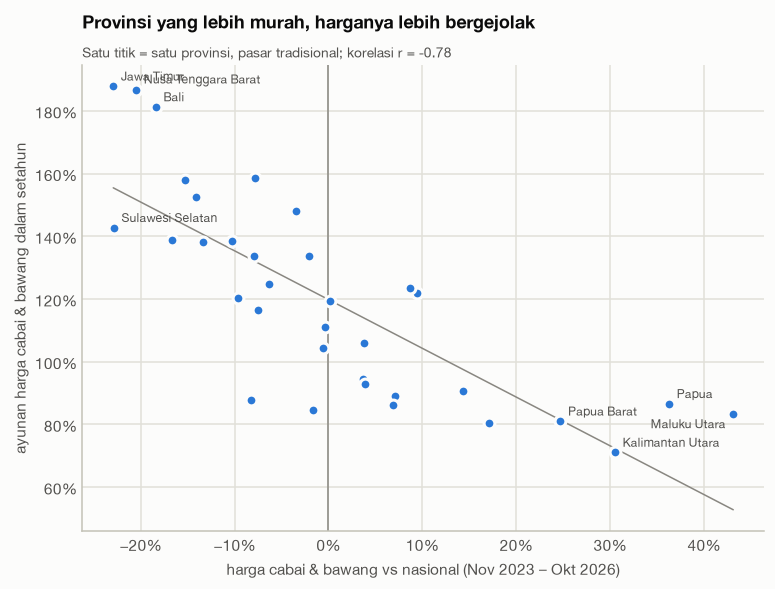

In [4]:
r = fitur.level_bumbu.corr(fitur.ayunan_cabai_bawang)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(fitur.level_bumbu, fitur.ayunan_cabai_bawang, s=50, color=SERIES[0],
           edgecolor="#fcfcfb", linewidth=2, zorder=3)
z = np.polyfit(fitur.level_bumbu, fitur.ayunan_cabai_bawang, 1)
xs = np.linspace(fitur.level_bumbu.min(), fitur.level_bumbu.max(), 50)
ax.plot(xs, np.polyval(z, xs), color=MUTED, linewidth=1)
ekstrem = pd.concat([fitur.nlargest(4, "level_bumbu"), fitur.nsmallest(4, "level_bumbu"),
                     fitur.nlargest(3, "ayunan_cabai_bawang")]).index.unique()
ax.axvline(0, color=MUTED, linewidth=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("harga cabai & bawang vs nasional (Nov 2023 – Okt 2026)")
ax.set_ylabel("ayunan harga cabai & bawang dalam setahun")
label_titik(ax, fitur.loc[ekstrem, "level_bumbu"], fitur.loc[ekstrem, "ayunan_cabai_bawang"], ekstrem, fontsize=8)
ax.set_title("Provinsi yang lebih murah, harganya lebih bergejolak", pad=24)
subtitle(ax, f"Satu titik = satu provinsi, pasar tradisional; korelasi r = {r:.2f}")
save(fig, "04_level_vs_ayunan")
plt.show()

**Kenapa begitu?** Dua penjelasan yang masuk akal (tidak bisa dibuktikan dari data ini saja):
- Provinsi sentra produksi (Jawa Tengah, Jawa Timur, NTB, Sulawesi Selatan) langsung terkena
  siklus panen: harga anjlok saat panen raya dan melonjak saat gagal panen.
- Di provinsi yang jauh dari sentra, harga sudah mengandung ongkos kirim yang relatif tetap.
  Komponen tetap ini membuat **persentase** naik-turunnya lebih kecil, walaupun harganya lebih mahal.

## 2. Memilih jumlah cluster

Fitur distandardisasi (z-score) supaya skala persen level harga dan ayunan setara. Untuk setiap
k dihitung:
- **silhouette** KMeans dan Ward (makin tinggi, makin terpisah clusternya)
- **kesepakatan KMeans vs Ward** (adjusted Rand index): apakah dua metode berbeda memberi hasil sama
- **stabilitas bootstrap**: median ARI antara cluster asli dan cluster dari 200 sampel bootstrap

In [5]:
Z = StandardScaler().fit_transform(fitur[FITUR])
rng = np.random.default_rng(0)
rows = []
for k in range(2, 7):
    km = KMeans(k, n_init=50, random_state=0).fit(Z)
    ward = AgglomerativeClustering(k, linkage="ward").fit(Z)
    boot = []
    for _ in range(200):
        idx = rng.choice(len(Z), len(Z), replace=True)
        kb = KMeans(k, n_init=10, random_state=0).fit(Z[idx])
        boot.append(adjusted_rand_score(km.labels_, kb.predict(Z)))
    rows.append({"k": k, "silhouette_kmeans": silhouette_score(Z, km.labels_),
                 "silhouette_ward": silhouette_score(Z, ward.labels_),
                 "kmeans_vs_ward": adjusted_rand_score(km.labels_, ward.labels_),
                 "stabilitas_bootstrap": np.median(boot),
                 "ukuran_cluster": sorted(np.bincount(km.labels_), reverse=True)})
pilih_k = pd.DataFrame(rows).set_index("k")
pilih_k

,silhouette_kmeans,silhouette_ward,kmeans_vs_ward,stabilitas_bootstrap,ukuran_cluster
k,,,,,
2,0.398,0.480,0.203,0.669,"[19, 15]"
3,0.384,0.392,0.895,0.895,"[15, 13, 6]"
4,0.335,0.312,0.941,0.657,"[14, 9, 6, 5]"
5,0.314,0.293,0.930,0.616,"[11, 9, 6, 5, 3]"
6,0.337,0.315,0.935,0.606,"[11, 7, 6, 5, 3, 2]"


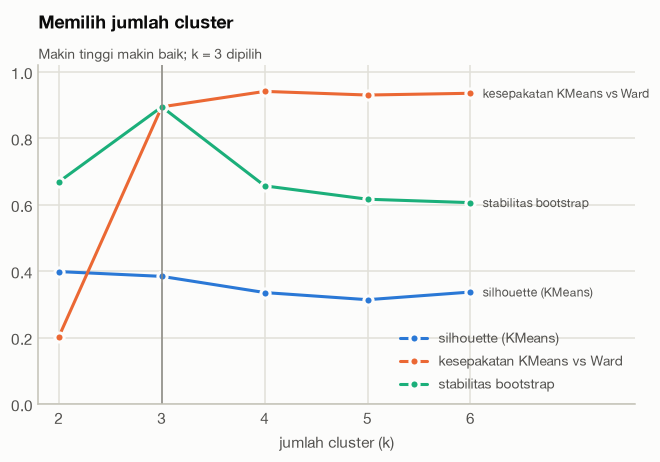

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for kolom, c, label in [("silhouette_kmeans", SERIES[0], "silhouette (KMeans)"),
                        ("kmeans_vs_ward", SERIES[1], "kesepakatan KMeans vs Ward"),
                        ("stabilitas_bootstrap", SERIES[2], "stabilitas bootstrap")]:
    ax.plot(pilih_k.index, pilih_k[kolom], "-o", color=c, markersize=6, label=label,
            markeredgecolor="#fcfcfb", markeredgewidth=2)
    ax.annotate(label, (6, pilih_k[kolom].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                fontsize=8, color=INK_2, va="center")
ax.axvline(3, color=MUTED, linewidth=1)
ax.set_xticks(pilih_k.index)
ax.set_xlim(1.8, 7.6)
ax.set_ylim(0, 1.02)
ax.set_xlabel("jumlah cluster (k)")
ax.legend(loc="lower right")
ax.set_title("Memilih jumlah cluster", pad=24)
subtitle(ax, "Makin tinggi makin baik; k = 3 dipilih")
save(fig, "04_pilih_k")
plt.show()

**Pilihan: k = 3.** Silhouette k = 2 dan k = 3 hampir sama (0,40 vs 0,38), tetapi k = 3 jauh lebih
stabil: KMeans dan Ward hampir sepakat (ARI 0,89) dan hasilnya bertahan di sampel bootstrap
(0,89). Untuk k ≥ 4, silhouette dan stabilitas turun.

Catatan jujur: silhouette 0,38 artinya struktur clusternya **sedang**, bukan sangat tegas. Provinsi
lebih tepat dilihat sebagai satu spektrum (murah & bergejolak → mahal & stabil) yang dibagi tiga,
bukan tiga kelompok yang benar-benar terpisah.

## 3. Profil cluster

In [7]:
km = KMeans(3, n_init=50, random_state=0).fit(Z)
fitur["cluster_id"] = km.labels_
# beri nama berdasarkan urutan level harga bumbu: termurah -> termahal
urut = fitur.groupby("cluster_id").level_bumbu.mean().sort_values().index
NAMA = dict(zip(urut, ["Murah tapi bergejolak", "Mendekati rata-rata", "Mahal tapi stabil"]))
fitur["cluster"] = fitur.cluster_id.map(NAMA)
URUTAN_CLUSTER = list(NAMA[i] for i in urut)

profil = fitur.groupby("cluster")[FITUR].mean().loc[URUTAN_CLUSTER]
profil["n_provinsi"] = fitur.cluster.value_counts()
profil

,level_pokok,level_protein,level_bumbu,ayunan_cabai_bawang,n_provinsi
cluster,,,,,
Murah tapi bergejolak,-0.039,-0.070,-0.138,1.531,13
Mendekati rata-rata,-0.001,0.009,0.009,1.062,15
Mahal tapi stabil,0.089,0.131,0.277,0.822,6


In [8]:
for c in URUTAN_CLUSTER:
    anggota = fitur[fitur.cluster == c].sort_values("level_bumbu").index
    print(f"{c} ({len(anggota)}): {', '.join(anggota)}\n")

Murah tapi bergejolak (13): Jawa Timur, Sulawesi Selatan, Nusa Tenggara Barat, Bali, Sulawesi Barat, Jawa Tengah, Jambi, Sumatera Utara, Lampung, Bengkulu, DI Yogyakarta, Riau, Banten

Mendekati rata-rata (15): Kalimantan Selatan, Aceh, Sumatera Barat, Jawa Barat, Kepulauan Riau, Sumatera Selatan, Sulawesi Tengah, Sulawesi Utara, Kalimantan Timur, Gorontalo, Nusa Tenggara Timur, Kepulauan Bangka Belitung, Kalimantan Barat, Sulawesi Tenggara, DKI Jakarta

Mahal tapi stabil (6): Kalimantan Tengah, Maluku, Papua Barat, Kalimantan Utara, Papua, Maluku Utara



In [9]:
pd.crosstab(info.loc[fitur.index, "pulau"], fitur.cluster)[URUTAN_CLUSTER]

cluster,Murah tapi bergejolak,Mendekati rata-rata,Mahal tapi stabil
pulau,,,
Bali & Nusa Tenggara,2,1,0
Jawa,4,2,0
Kalimantan,0,3,2
Maluku & Papua,0,0,4
Sulawesi,2,4,0
Sumatera,5,5,0


In [10]:
pca = PCA(2).fit(Z)
print(f"Variansi yang dijelaskan PC1, PC2: {pca.explained_variance_ratio_.round(2)}")
pd.DataFrame(pca.components_.T, index=FITUR, columns=["PC1", "PC2"])

Variansi yang dijelaskan PC1, PC2: [0.79 0.12]


,PC1,PC2
level_pokok,0.495,0.509
level_protein,0.506,0.371
level_bumbu,0.529,-0.160
ayunan_cabai_bawang,-0.467,0.760


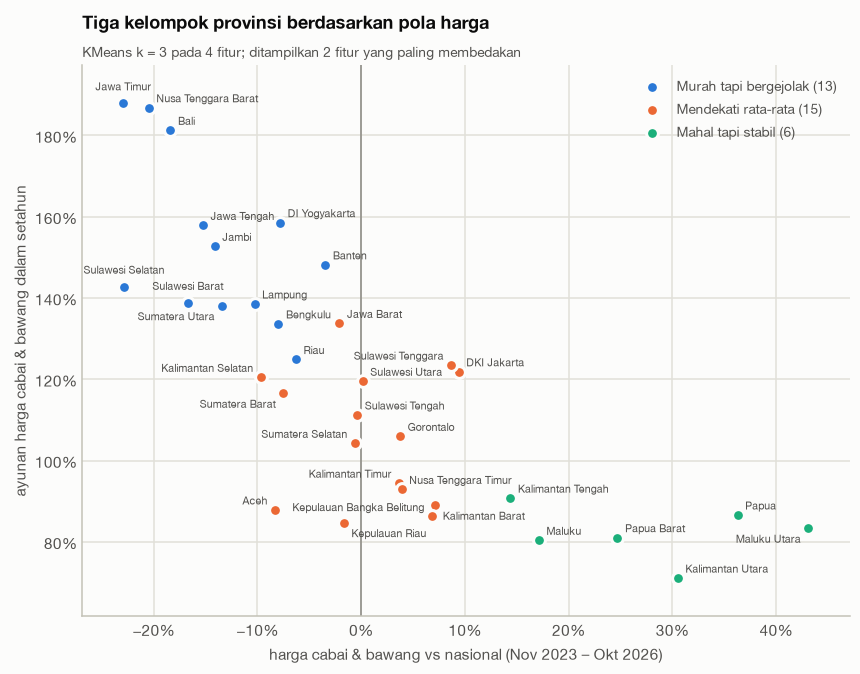

In [11]:
WARNA_CLUSTER = dict(zip(URUTAN_CLUSTER, SERIES_ALL_PAIRS))
fig, ax = plt.subplots(figsize=(9, 6.5))
for c in URUTAN_CLUSTER:
    d = fitur[fitur.cluster == c]
    ax.scatter(d.level_bumbu, d.ayunan_cabai_bawang, s=60, color=WARNA_CLUSTER[c], label=f"{c} ({len(d)})",
               edgecolor="#fcfcfb", linewidth=2, zorder=3)
ax.axvline(0, color=MUTED, linewidth=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("harga cabai & bawang vs nasional (Nov 2023 – Okt 2026)")
ax.set_ylabel("ayunan harga cabai & bawang dalam setahun")
ax.legend(loc="upper right", title=None)
ax.margins(x=0.06, y=0.08)
label_titik(ax, fitur.level_bumbu, fitur.ayunan_cabai_bawang, fitur.index)
ax.set_title("Tiga kelompok provinsi berdasarkan pola harga", pad=24)
subtitle(ax, "KMeans k = 3 pada 4 fitur; ditampilkan 2 fitur yang paling membedakan")
save(fig, "04_cluster_provinsi")
plt.show()

**Insight:**

| Cluster | Provinsi | Harga bumbu | Harga protein | Harga pokok | Ayunan cabai & bawang |
|---|---|---|---|---|---|
| **Murah tapi bergejolak** (13) | Jawa Timur, Jawa Tengah, DIY, Banten, Bali, NTB, Sulawesi Selatan, Sulawesi Barat, Sumatera Utara, Jambi, Lampung, Bengkulu, Riau | −14% | −7% | −4% | **153%** per tahun |
| **Mendekati rata-rata** (15) | Jawa Barat, DKI Jakarta, Aceh, Sumatera Barat, Sumatera Selatan, Kepulauan Riau, Bangka Belitung, Kalimantan Barat, Selatan, Timur, Sulawesi Utara, Tengah, Tenggara, Gorontalo, NTT | ±1% | ±1% | ±0% | 106% |
| **Mahal tapi stabil** (6) | Maluku, Maluku Utara, Papua, Papua Barat, Kalimantan Tengah, Kalimantan Utara | **+28%** | +13% | +9% | 82% |

- Cluster **tidak sama dengan pulau**. Jawa terbagi dua (Jawa Barat dan DKI Jakarta masuk
  "mendekati rata-rata"), Sumatera terbagi rata, dan Kalimantan Tengah & Utara masuk kelompok
  yang sama dengan Maluku & Papua.
- Cluster "murah tapi bergejolak" berisi sentra produksi (Jawa Timur, Jawa Tengah, NTB,
  Sulawesi Selatan, Lampung). Kelompok "mahal tapi stabil" adalah provinsi yang jauh dari sentra.
- Satu dimensi utama (PC1) menjelaskan 79% variansi: provinsi berjajar dari "murah & bergejolak" ke
  "mahal & stabil". Ini juga cocok dengan Q7: Maluku & Papua punya pass-through terkecil dari Jawa.

## 4. Ekspor untuk Tableau

Hasil cluster disimpan ke `data/exports/cluster_provinsi.csv` supaya bisa ditampilkan di peta
dashboard Tableau (Fase 5).

In [12]:
ekspor = (fitur.join(info).reset_index()
          [["wilayah_id", "nama_wilayah", "pulau", "cluster", *FITUR]]
          .sort_values(["cluster", "nama_wilayah"]))
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
ekspor.to_csv(EXPORT_DIR / "cluster_provinsi.csv", index=False, float_format="%.4f")
print(f"Tersimpan: data/exports/cluster_provinsi.csv ({len(ekspor)} baris)")
ekspor.head()

Tersimpan: data/exports/cluster_provinsi.csv (34 baris)


,wilayah_id,nama_wilayah,pulau,cluster,level_pokok,level_protein,level_bumbu,ayunan_cabai_bawang
13,22,Kalimantan Tengah,Kalimantan,Mahal tapi stabil,0.094,0.066,0.144,0.908
15,24,Kalimantan Utara,Kalimantan,Mahal tapi stabil,0.038,0.092,0.305,0.711
19,31,Maluku,Maluku & Papua,Mahal tapi stabil,0.066,0.116,0.171,0.804
20,32,Maluku Utara,Maluku & Papua,Mahal tapi stabil,0.092,0.142,0.431,0.833
23,33,Papua,Maluku & Papua,Mahal tapi stabil,0.157,0.179,0.363,0.866


## Ringkasan Q8

**Jawaban Q8: ya.** Provinsi bisa dikelompokkan menjadi 3 cluster yang stabil (KMeans dan Ward
sepakat, ARI 0,89; stabil di bootstrap, ARI 0,89), walaupun strukturnya sedang (silhouette 0,38).

**Playbook procurement per cluster:**

| Cluster | Risiko utama | Strategi |
|---|---|---|
| Murah tapi bergejolak | Ayunan harga cabai & bawang ±150% per tahun | Beli lokal (harga termurah), tapi kunci harga cabai & bawang lewat kontrak atau forward buying; tambah stok bawang di Sep–Okt (Q5). Bisa jadi **hub pasokan** untuk cluster lain. |
| Mendekati rata-rata | Ikut terkena lonjakan dari Jawa dalam 1–2 minggu (Q7) | Anggaran standar nasional; pantau harga mingguan di sentra Jawa sebagai peringatan dini. |
| Mahal tapi stabil | Level harga, bukan gejolak: bumbu +28%, protein +13% | Anggaran premium 10–30%; fokus ke ongkos kirim dan kontrak jangka panjang dengan supplier tetap. Kaji pasokan dari hub Sulawesi Selatan / Jawa Timur (hitung ongkos kirim dulu). |

Hasil cluster: `data/exports/cluster_provinsi.csv` (untuk peta di Tableau).